# Notebook 03 — Cheating Behavior Signals

## AI Exam Cheating Tracking Project

This notebook adds **behavior signals** on top of student tracking.

### Goal
For each tracked student, estimate:
- `phone_detected`
- `head_direction` → left / right / forward / unknown
- `side_look_duration`
- `head_turn_count`

### Important
This notebook does **not** make the final cheating decision yet.

It only extracts behavioral signals for each `Track ID`.

The final decision logic (Normal / Cheating, Green / Red, Screenshot) will be added in Notebook 04.


## 1. Install packages

In [1]:
!pip install -q ultralytics opencv-python pandas matplotlib

## 2. Imports and GPU check

In [2]:
from pathlib import Path
from collections import defaultdict, deque

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO
from google.colab import drive
from IPython.display import Video, display

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. Mount Google Drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Project paths

In [4]:
BASE_DIR = Path("/content/drive/MyDrive/cheating tracking")
VIDEO_DIR = BASE_DIR / "videos"

OUTPUT_DIR = BASE_DIR / "outputs"
BEHAVIOR_DIR = OUTPUT_DIR / "behavior_signals"

TRACKER_CONFIG = BASE_DIR / "tracker_configs" / "bytetrack_exam.yaml"

BEHAVIOR_DIR.mkdir(parents=True, exist_ok=True)

print("VIDEO_DIR:", VIDEO_DIR)
print("BEHAVIOR_DIR:", BEHAVIOR_DIR)
print("TRACKER_CONFIG:", TRACKER_CONFIG)


VIDEO_DIR: /content/drive/MyDrive/cheating tracking/videos
BEHAVIOR_DIR: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals
TRACKER_CONFIG: /content/drive/MyDrive/cheating tracking/tracker_configs/bytetrack_exam.yaml


## 5. Load videos

In [5]:
video_files = sorted(
    list(VIDEO_DIR.glob("*.mp4")) +
    list(VIDEO_DIR.glob("*.avi")) +
    list(VIDEO_DIR.glob("*.mov")) +
    list(VIDEO_DIR.glob("*.mkv"))
)

for i, video in enumerate(video_files):
    print(i, "->", video.name)

assert len(video_files) > 0, "No videos found."


0 -> video1.mp4
1 -> video2.mp4
2 -> video3.mp4
3 -> video4.mp4


## 6. Load the models

We use:

### Detection + Tracking
`yolo11n.pt`

Used for:
- person
- cell phone

### Pose
`yolo11n-pose.pt`

Used for human keypoints such as:
- nose
- eyes
- ears
- shoulders

These keypoints help estimate head direction.


In [6]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"

tracking_model = YOLO("yolo11n.pt")
pose_model = YOLO("yolo11n-pose.pt")

print("Models loaded.")
print("Device:", DEVICE)


Models loaded.
Device: 0


## 7. COCO classes

The pretrained YOLO detection model uses COCO classes.

We need:

- `person = 0`
- `cell phone = 67`


In [7]:
PERSON_CLASS = 0
CELL_PHONE_CLASS = 67

print("Person class:", PERSON_CLASS)
print("Cell phone class:", CELL_PHONE_CLASS)


Person class: 0
Cell phone class: 67


## 8. Helper geometry functions

In [8]:
def box_center(box):
    x1, y1, x2, y2 = box
    return (
        (x1 + x2) / 2,
        (y1 + y2) / 2
    )


def expand_box(box, frame_shape, scale_x=0.25, scale_y=0.15):
    frame_h, frame_w = frame_shape[:2]

    x1, y1, x2, y2 = map(float, box)

    bw = x2 - x1
    bh = y2 - y1

    return (
        max(0, x1 - bw * scale_x),
        max(0, y1 - bh * scale_y),
        min(frame_w - 1, x2 + bw * scale_x),
        min(frame_h - 1, y2 + bh * scale_y)
    )


def point_inside_box(point, box):
    x, y = point
    x1, y1, x2, y2 = box

    return (
        x1 <= x <= x2
        and
        y1 <= y <= y2
    )


def box_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)

    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)
    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)

    intersection = inter_w * inter_h

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0


## 9. Head direction heuristic

COCO pose keypoints:

```text
0 = nose
1 = left eye
2 = right eye
3 = left ear
4 = right ear
```

We estimate:

```text
left
right
forward
unknown
```

This is a lightweight heuristic, not a true gaze estimator.


In [9]:
NOSE = 0
LEFT_EYE = 1
RIGHT_EYE = 2
LEFT_EAR = 3
RIGHT_EAR = 4


def estimate_head_direction(keypoints_xy, keypoints_conf=None):
    xy = np.asarray(keypoints_xy, dtype=float)

    if xy.ndim != 2 or xy.shape[0] < 5:
        return "unknown"

    if keypoints_conf is None:
        conf = np.ones(xy.shape[0], dtype=float)
    else:
        conf = np.asarray(keypoints_conf, dtype=float)

    def visible(index, threshold=0.25):
        return (
            index < len(conf)
            and conf[index] >= threshold
            and xy[index, 0] > 0
            and xy[index, 1] > 0
        )

    # Strongest case: nose and both eyes visible
    if (
        visible(NOSE)
        and visible(LEFT_EYE)
        and visible(RIGHT_EYE)
    ):
        nose_x = xy[NOSE, 0]

        left_eye_x = xy[LEFT_EYE, 0]
        right_eye_x = xy[RIGHT_EYE, 0]

        eye_mid = (left_eye_x + right_eye_x) / 2
        eye_distance = abs(left_eye_x - right_eye_x)

        if eye_distance >= 3:
            offset = (
                nose_x - eye_mid
            ) / eye_distance

            if offset > 0.28:
                return "right"

            elif offset < -0.28:
                return "left"

            else:
                return "forward"

    # Backup heuristic
    left_side_visible = (
        visible(LEFT_EYE)
        or visible(LEFT_EAR)
    )

    right_side_visible = (
        visible(RIGHT_EYE)
        or visible(RIGHT_EAR)
    )

    if left_side_visible and not right_side_visible:
        return "right"

    if right_side_visible and not left_side_visible:
        return "left"

    return "unknown"


## 10. Match pose detections with tracked students

In [10]:
def match_pose_to_tracks(
    tracked_students,
    pose_boxes,
    pose_keypoints_xy,
    pose_keypoints_conf
):
    directions = {}

    for pose_index, pose_box in enumerate(pose_boxes):

        best_track_id = None
        best_iou = 0

        for student in tracked_students:

            score = box_iou(
                student["box"],
                pose_box
            )

            if score > best_iou:
                best_iou = score
                best_track_id = student["track_id"]

        if (
            best_track_id is not None
            and best_iou >= 0.20
        ):
            kp_conf = None

            if (
                pose_keypoints_conf is not None
                and pose_index < len(pose_keypoints_conf)
            ):
                kp_conf = pose_keypoints_conf[pose_index]

            direction = estimate_head_direction(
                pose_keypoints_xy[pose_index],
                kp_conf
            )

            directions[best_track_id] = direction

    return directions


## 11. Phone-to-student association

If the center of a detected phone lies inside an expanded student bounding box, we associate that phone with the student.


In [11]:
def phone_near_student(
    student_box,
    phone_detections,
    frame_shape
):
    search_box = expand_box(
        student_box,
        frame_shape,
        scale_x=0.25,
        scale_y=0.15
    )

    best_phone = None
    best_conf = 0

    for phone in phone_detections:

        center = box_center(
            phone["box"]
        )

        if point_inside_box(
            center,
            search_box
        ):
            if phone["confidence"] > best_conf:
                best_conf = phone["confidence"]
                best_phone = phone

    return best_phone


## 12. Behavior memory

We maintain temporal state for every Track ID.

For each student we store:
- current side-looking start time
- previous head direction
- recent left/right switches


In [12]:
class BehaviorState:
    def __init__(self):
        self.last_direction = "unknown"
        self.side_started_at = None
        self.direction_changes = deque()


behavior_states = defaultdict(BehaviorState)


## 13. Update temporal behavior signals

In [13]:
HEAD_TURN_WINDOW = 8.0


def update_behavior_state(
    track_id,
    direction,
    video_time
):
    state = behavior_states[track_id]

    side_duration = 0.0

    if direction in {"left", "right"}:

        # Count left/right switches
        if (
            state.last_direction in {"left", "right"}
            and direction != state.last_direction
        ):
            state.direction_changes.append(
                video_time
            )

        # Remove old turns
        while (
            state.direction_changes
            and
            video_time - state.direction_changes[0]
            > HEAD_TURN_WINDOW
        ):
            state.direction_changes.popleft()

        # Start sideways timer
        if state.side_started_at is None:
            state.side_started_at = video_time

        side_duration = (
            video_time - state.side_started_at
        )

    else:
        state.side_started_at = None
        side_duration = 0.0

    if direction != "unknown":
        state.last_direction = direction

    return {
        "side_look_duration": side_duration,
        "head_turn_count": len(
            state.direction_changes
        )
    }


## 14. Process one video and extract signals

This stage combines:

```text
YOLO11 detection
+
ByteTrack
+
YOLO11 Pose
+
Phone association
+
Temporal behavior memory
```

Still **no cheating decision**.


In [14]:
def extract_behavior_signals(
    input_video,
    output_video,
    output_csv,
    detection_conf=0.30,
    pose_conf=0.30,
    pose_stride=3
):
    global behavior_states

    behavior_states = defaultdict(BehaviorState)

    tracker_model = YOLO("yolo11n.pt")
    pose_detector = YOLO("yolo11n-pose.pt")

    cap = cv2.VideoCapture(
        str(input_video)
    )

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    width = int(
        cap.get(
            cv2.CAP_PROP_FRAME_WIDTH
        )
    )

    height = int(
        cap.get(
            cv2.CAP_PROP_FRAME_HEIGHT
        )
    )

    fourcc = cv2.VideoWriter_fourcc(
        *"mp4v"
    )

    writer = cv2.VideoWriter(
        str(output_video),
        fourcc,
        fps,
        (width, height)
    )

    records = []

    last_head_direction = {}

    frame_index = 0

    while True:

        ok, frame = cap.read()

        if not ok:
            break

        video_time = (
            frame_index / fps
            if fps > 0
            else 0
        )

        # -------------------------
        # Detection + Tracking
        # -------------------------

        result = tracker_model.track(
            source=frame,
            persist=True,
            tracker=str(TRACKER_CONFIG),
            classes=[
                PERSON_CLASS,
                CELL_PHONE_CLASS
            ],
            conf=detection_conf,
            device=DEVICE,
            verbose=False
        )[0]

        students = []
        phones = []

        if (
            result.boxes is not None
            and len(result.boxes) > 0
        ):
            boxes = (
                result.boxes.xyxy
                .cpu()
                .numpy()
            )

            classes = (
                result.boxes.cls
                .int()
                .cpu()
                .tolist()
            )

            confidences = (
                result.boxes.conf
                .cpu()
                .tolist()
            )

            if result.boxes.id is not None:
                ids = (
                    result.boxes.id
                    .int()
                    .cpu()
                    .tolist()
                )
            else:
                ids = [-1] * len(boxes)

            for box, cls_id, conf, tid in zip(
                boxes,
                classes,
                confidences,
                ids
            ):
                item = {
                    "box": tuple(
                        map(float, box)
                    ),
                    "confidence": float(conf),
                    "track_id": int(tid)
                }

                if (
                    cls_id == PERSON_CLASS
                    and tid >= 0
                ):
                    students.append(item)

                elif cls_id == CELL_PHONE_CLASS:
                    phones.append(item)

        # -------------------------
        # Pose
        # -------------------------

        if (
            frame_index
            % max(1, pose_stride)
            == 0
            and len(students) > 0
        ):
            pose_result = pose_detector.predict(
                source=frame,
                conf=pose_conf,
                device=DEVICE,
                verbose=False
            )[0]

            if (
                pose_result.boxes is not None
                and pose_result.keypoints is not None
            ):
                pose_boxes = (
                    pose_result.boxes.xyxy
                    .cpu()
                    .numpy()
                )

                kp_xy = (
                    pose_result.keypoints.xy
                    .cpu()
                    .numpy()
                )

                kp_conf = None

                if (
                    pose_result.keypoints.conf
                    is not None
                ):
                    kp_conf = (
                        pose_result.keypoints.conf
                        .cpu()
                        .numpy()
                    )

                directions = match_pose_to_tracks(
                    students,
                    pose_boxes,
                    kp_xy,
                    kp_conf
                )

                last_head_direction.update(
                    directions
                )

        annotated = frame.copy()

        # -------------------------
        # Draw detected phones
        # -------------------------

        for phone in phones:

            x1, y1, x2, y2 = map(
                int,
                phone["box"]
            )

            cv2.rectangle(
                annotated,
                (x1, y1),
                (x2, y2),
                (0, 165, 255),
                2
            )

            cv2.putText(
                annotated,
                f"Phone {phone['confidence']:.2f}",
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 165, 255),
                2
            )

        # -------------------------
        # Student signals
        # -------------------------

        for student in students:

            tid = student["track_id"]

            x1, y1, x2, y2 = map(
                int,
                student["box"]
            )

            direction = (
                last_head_direction.get(
                    tid,
                    "unknown"
                )
            )

            temporal = update_behavior_state(
                tid,
                direction,
                video_time
            )

            phone = phone_near_student(
                student["box"],
                phones,
                frame.shape
            )

            phone_detected = (
                phone is not None
            )

            phone_confidence = (
                phone["confidence"]
                if phone is not None
                else 0.0
            )

            # Save row
            records.append({
                "video": input_video.name,
                "frame": frame_index,
                "time_sec": round(
                    video_time,
                    3
                ),
                "track_id": tid,
                "person_confidence": round(
                    student["confidence"],
                    4
                ),
                "head_direction": direction,
                "side_look_duration": round(
                    temporal[
                        "side_look_duration"
                    ],
                    3
                ),
                "head_turn_count": temporal[
                    "head_turn_count"
                ],
                "phone_detected": phone_detected,
                "phone_confidence": round(
                    float(
                        phone_confidence
                    ),
                    4
                )
            })

            # Green box only for now
            cv2.rectangle(
                annotated,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            label1 = (
                f"ID {tid} | "
                f"head:{direction}"
            )

            label2 = (
                f"side:{temporal['side_look_duration']:.1f}s "
                f"| turns:{temporal['head_turn_count']} "
                f"| phone:{phone_detected}"
            )

            cv2.putText(
                annotated,
                label1,
                (x1, max(20, y1 - 28)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.60,
                (0, 255, 0),
                2
            )

            cv2.putText(
                annotated,
                label2,
                (x1, max(20, y1 - 7)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.50,
                (0, 255, 0),
                2
            )

        writer.write(
            annotated
        )

        frame_index += 1

        if frame_index % 50 == 0:
            print(
                f"{input_video.name}: "
                f"{frame_index}/{total_frames}"
            )

    cap.release()
    writer.release()

    df = pd.DataFrame(records)
    df.to_csv(
        output_csv,
        index=False
    )

    print()
    print("Finished:", input_video.name)
    print("Saved video:", output_video)
    print("Saved CSV:", output_csv)

    return df


## 15. Run on one video first

In [15]:
TEST_VIDEO = video_files[0]

OUTPUT_VIDEO = (
    BEHAVIOR_DIR /
    f"{TEST_VIDEO.stem}_behavior_signals.mp4"
)

OUTPUT_CSV = (
    BEHAVIOR_DIR /
    f"{TEST_VIDEO.stem}_behavior_signals.csv"
)

behavior_df = extract_behavior_signals(
    TEST_VIDEO,
    OUTPUT_VIDEO,
    OUTPUT_CSV
)

behavior_df.head(20)


requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 152ms
Prepared 1 package in 22ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

video1.mp4: 50/488
video1.mp4: 100/488
video1.mp4: 150/488
video1.mp4: 200/488
video1.mp4: 250/488
video1.mp4: 300/488
video1.mp4: 350/488
video1.mp4: 400/488
video1.mp4: 450/488

Finished: video1.mp4
Saved video: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video1_behavior_signals.mp4
Saved CSV: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video1_behavior_signals.csv


,video,frame,time_sec,track_id,person_confidence,head_direction,side_look_duration,head_turn_count,phone_detected,phone_confidence
0,video1.mp4,0,0.000,1,0.9518,forward,0.0,0,False,0.0
1,video1.mp4,0,0.000,2,0.9348,forward,0.0,0,False,0.0
2,video1.mp4,0,0.000,3,0.6397,forward,0.0,0,False,0.0
3,video1.mp4,1,0.042,1,0.9503,forward,0.0,0,False,0.0
4,video1.mp4,1,0.042,2,0.9361,forward,0.0,0,False,0.0
5,video1.mp4,1,0.042,3,0.5009,forward,0.0,0,False,0.0
6,video1.mp4,2,0.083,1,0.9511,forward,0.0,0,False,0.0
7,video1.mp4,2,0.083,2,0.9361,forward,0.0,0,False,0.0
8,video1.mp4,2,0.083,3,0.5037,forward,0.0,0,False,0.0
9,video1.mp4,3,0.125,1,0.9499,forward,0.0,0,False,0.0


## 16. Preview processed video

In [16]:
display(
    Video(
        str(OUTPUT_VIDEO),
        embed=True,
        width=900
    )
)


Output hidden; open in https://colab.research.google.com to view.

## 17. Inspect behavior signals

In [17]:
print("Rows:", len(behavior_df))

print()
print("Track IDs:")
print(
    sorted(
        behavior_df[
            "track_id"
        ].unique()
    )
)

print()
print("Head direction counts:")
display(
    behavior_df[
        "head_direction"
    ].value_counts()
)

print()
print("Phone detections:")
display(
    behavior_df[
        "phone_detected"
    ].value_counts()
)


Rows: 1591

Track IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8)]

Head direction counts:


,count
head_direction,
forward,1347
unknown,154
right,48
left,42



Phone detections:


,count
phone_detected,
False,1544
True,47


## 18. Maximum side-look duration per student

In [18]:
side_summary = (
    behavior_df
    .groupby("track_id")
    .agg(
        max_side_look_seconds=(
            "side_look_duration",
            "max"
        ),
        max_head_turn_count=(
            "head_turn_count",
            "max"
        ),
        phone_frames=(
            "phone_detected",
            "sum"
        )
    )
    .reset_index()
)

side_summary


,track_id,max_side_look_seconds,max_head_turn_count,phone_frames
0,1,0.000,0,47
1,2,0.000,0,0
2,3,1.958,0,0
3,4,1.458,0,0
4,6,0.000,0,0
5,7,0.000,0,0
6,8,0.000,0,0


## 19. Plot head direction over time for one student

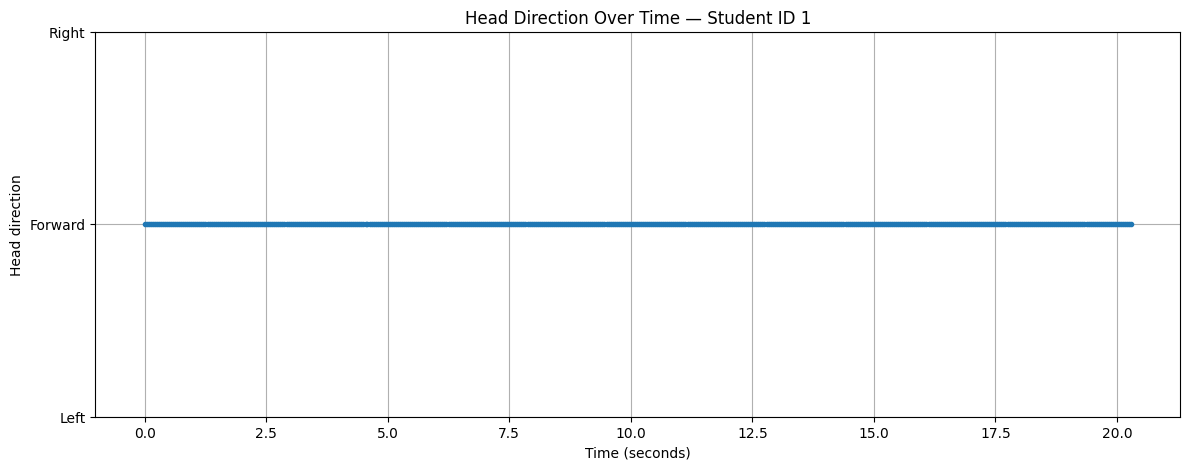

In [19]:
available_ids = sorted(
    behavior_df[
        "track_id"
    ].unique()
)

STUDENT_ID = available_ids[0]

student_df = behavior_df[
    behavior_df["track_id"]
    == STUDENT_ID
].copy()

direction_map = {
    "left": -1,
    "forward": 0,
    "right": 1,
    "unknown": np.nan
}

student_df[
    "direction_numeric"
] = student_df[
    "head_direction"
].map(
    direction_map
)

plt.figure(figsize=(14, 5))

plt.plot(
    student_df["time_sec"],
    student_df["direction_numeric"],
    marker=".",
    linestyle="-"
)

plt.yticks(
    [-1, 0, 1],
    ["Left", "Forward", "Right"]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Head direction")
plt.title(
    f"Head Direction Over Time — Student ID {STUDENT_ID}"
)

plt.grid(True)
plt.show()


## 20. Optional — Process all videos

Run this after verifying the first video.


In [20]:
all_behavior_summaries = []

for video_path in video_files:

    output_video = (
        BEHAVIOR_DIR /
        f"{video_path.stem}_behavior_signals.mp4"
    )

    output_csv = (
        BEHAVIOR_DIR /
        f"{video_path.stem}_behavior_signals.csv"
    )

    df = extract_behavior_signals(
        video_path,
        output_video,
        output_csv
    )

    summary = (
        df
        .groupby("track_id")
        .agg(
            max_side_look_seconds=(
                "side_look_duration",
                "max"
            ),
            max_head_turn_count=(
                "head_turn_count",
                "max"
            ),
            phone_frames=(
                "phone_detected",
                "sum"
            )
        )
        .reset_index()
    )

    summary["video"] = video_path.name

    all_behavior_summaries.append(
        summary
    )

all_behavior_summary_df = pd.concat(
    all_behavior_summaries,
    ignore_index=True
)

all_behavior_summary_df


video1.mp4: 50/488
video1.mp4: 100/488
video1.mp4: 150/488
video1.mp4: 200/488
video1.mp4: 250/488
video1.mp4: 300/488
video1.mp4: 350/488
video1.mp4: 400/488
video1.mp4: 450/488

Finished: video1.mp4
Saved video: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video1_behavior_signals.mp4
Saved CSV: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video1_behavior_signals.csv
video2.mp4: 50/261
video2.mp4: 100/261
video2.mp4: 150/261
video2.mp4: 200/261
video2.mp4: 250/261

Finished: video2.mp4
Saved video: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video2_behavior_signals.mp4
Saved CSV: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video2_behavior_signals.csv
video3.mp4: 50/256
video3.mp4: 100/256
video3.mp4: 150/256
video3.mp4: 200/256
video3.mp4: 250/256

Finished: video3.mp4
Saved video: /content/drive/MyDrive/cheating tracking/outputs/behavior_signals/video3_behavior_signals.mp4
Saved CSV: /content/drive/

,track_id,max_side_look_seconds,max_head_turn_count,phone_frames,video
0,1,0.000,0,47,video1.mp4
1,2,0.000,0,0,video1.mp4
2,3,1.958,0,0,video1.mp4
3,4,1.458,0,0,video1.mp4
4,6,0.000,0,0,video1.mp4
5,7,0.000,0,0,video1.mp4
6,8,0.000,0,0,video1.mp4
7,1,2.586,0,0,video2.mp4
8,2,0.000,0,0,video2.mp4
9,3,1.835,3,0,video2.mp4
